In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load and verify the dataset

In [2]:
import json

data_path = '/content/drive/MyDrive/en-US.jsonl'

with open(data_path, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

train_data = [r for r in records if r["partition"] == "train"]
dev_data   = [r for r in records if r["partition"] == "dev"]
test_data  = [r for r in records if r["partition"] == "test"]

print(f"Total examples:      {len(records)}")
print(f"Training examples:   {len(train_data)}")
print(f"Validation examples: {len(dev_data)}")
print(f"Test examples:       {len(test_data)}")

assert len(records) == 16521
assert len(train_data) == 11514
assert len(dev_data) == 2033
assert len(test_data) == 2974
print("All split sizes verified.")

print("\nExample record:", train_data[0])

Total examples:      16521
Training examples:   11514
Validation examples: 2033
Test examples:       2974
All split sizes verified.

Example record: {'id': '1', 'locale': 'en-US', 'partition': 'train', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'wake me up at nine am on friday', 'annot_utt': 'wake me up at [time : nine am] on [date : friday]', 'worker_id': '1'}


Preprocessing of data and setup

In [3]:
import json, os, re, time, random, tarfile, urllib.request
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [4]:
SLOT_RE = re.compile(r"\[\s*([^\]:]+?)\s*:\s*([^\]]*?)\s*\]")

def parse_annot(annot_utt):
    tokens, tags, pos = [], [], 0
    for m in SLOT_RE.finditer(annot_utt):
        for w in annot_utt[pos:m.start()].split():
            tokens.append(w); tags.append("O")
        slot_type = m.group(1).strip()
        for i, w in enumerate(m.group(2).split()):
            tokens.append(w); tags.append(("B-" if i == 0 else "I-") + slot_type)
        pos = m.end()
    for w in annot_utt[pos:].split():
        tokens.append(w); tags.append("O")
    return tokens, tags

def tags_to_spans(tokens, tags):
    """BIO tags -> set of (slot_type, span_text)."""
    spans, cur_type, cur_words = set(), None, []
    for tok, tag in zip(tokens, tags):
        if tag.startswith("B-") or (tag.startswith("I-") and tag[2:] != cur_type):
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = tag[2:], [tok]
        elif tag.startswith("I-"):
            cur_words.append(tok)
        else:
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = None, []
    if cur_type:
        spans.add((cur_type, " ".join(cur_words)))
    return spans

def preprocess(records):
    out = []
    for r in records:
        tokens, tags = parse_annot(r["annot_utt"])
        assert tokens == r["utt"].split(), f"Token mismatch in id {r['id']}"
        out.append({"id": r["id"], "tokens": tokens, "slot_tags": tags,
                    "intent": r["intent"], "gold_spans": tags_to_spans(tokens, tags)})
    return out

train_proc, dev_proc, test_proc = preprocess(train_data), preprocess(dev_data), preprocess(test_data)

# Vocab and label maps are built from the training split only
PAD, UNK = "<pad>", "<unk>"
word_counts = Counter(t.lower() for ex in train_proc for t in ex["tokens"])
word2id = {PAD: 0, UNK: 1}
for w, _ in word_counts.most_common():
    word2id[w] = len(word2id)

intent2id = {it: i for i, it in enumerate(sorted({ex["intent"] for ex in train_proc}))}
id2intent = {i: it for it, i in intent2id.items()}

# B- and I- for every slot type (I-transport_type only appears in test)
slot_types = sorted({t[2:] for ex in train_proc for t in ex["slot_tags"] if t != "O"})
slot2id = {"O": 0}
for st in slot_types:
    slot2id["B-" + st] = len(slot2id)
    slot2id["I-" + st] = len(slot2id)
id2slot = {i: s for s, i in slot2id.items()}

print(f"Vocab: {len(word2id)} | Intents: {len(intent2id)} | "
      f"Slot types: {len(slot_types)} | BIO tags: {len(slot2id)}")
assert len(intent2id) == 60 and len(slot_types) == 55

def encode(ex):
    return {"input_ids": [word2id.get(t.lower(), word2id[UNK]) for t in ex["tokens"]],
            "slot_ids": [slot2id[t] for t in ex["slot_tags"]],
            "intent_id": intent2id[ex["intent"]]}

SLOT_PAD_ID = -100  # ignored by CrossEntropyLoss

class MassiveDataset(Dataset):
    def __init__(self, proc):
        self.data = [encode(ex) for ex in proc]
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]

def collate_fn(batch):
    return {
        "input_ids": pad_sequence([torch.tensor(b["input_ids"]) for b in batch],
                                  batch_first=True, padding_value=word2id[PAD]),
        "slot_ids": pad_sequence([torch.tensor(b["slot_ids"]) for b in batch],
                                 batch_first=True, padding_value=SLOT_PAD_ID),
        "lengths": torch.tensor([len(b["input_ids"]) for b in batch]),
        "intent_id": torch.tensor([b["intent_id"] for b in batch]),
    }

train_ds, dev_ds, test_ds = MassiveDataset(train_proc), MassiveDataset(dev_proc), MassiveDataset(test_proc)
print("Example:", train_proc[0]["tokens"], train_proc[0]["slot_tags"], train_proc[0]["intent"])



Vocab: 5304 | Intents: 60 | Slot types: 55 | BIO tags: 111
Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'] ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date'] alarm_set


Shared Evaluation Functions

In [5]:
def intent_accuracy(pred_intents, gold_intents):
    correct = sum(p == g for p, g in zip(pred_intents, gold_intents))
    return 100.0 * correct / len(gold_intents)

def slot_micro_f1(pred_span_sets, gold_span_sets):
    tp = fp = fn = 0
    for pred, gold in zip(pred_span_sets, gold_span_sets):
        tp += len(pred & gold)
        fp += len(pred - gold)
        fn += len(gold - pred)
    denom = 2 * tp + fp + fn
    return 100.0 * 2 * tp / denom if denom > 0 else 0.0

## Stage 2: AI-enhanced system (joint BiLSTM-CRF ensemble)

**Weaknesses diagnosed from the Stage-1 run**
- Overfitting: training loss falls from 3.46 to 0.29, but validation loss rises after epoch 5 (1.15 to 1.45). Two randomly initialised 300-d embedding tables are learned from only 11.5k utterances.
- Unseen words: the vocabulary comes from the training split only, so every unseen dev/test word maps to the same `<unk>` vector. Unseen words are often slot values (names, places, titles).
- No interaction between the tasks: Model A and Model B share nothing, so the slot tagger never sees utterance-level (intent) context.
- Token-wise argmax tagging: nothing stops invalid BIO sequences (`O -> I-x`, `B-x -> I-y`) or boundary errors, and the exact-match span F1 metric penalises both.
- Optimisation: the learning rate stays constant apart from plateau halving, and the selected epoch is a single noisy snapshot.

**Stage-2 pipeline** (input: `utt` tokens, lower-cased; outputs: intent label plus the set of `(slot type, span)` pairs)
- Token representation: a frozen GloVe 6B 300-d vector, a trainable 100-d task embedding over the training vocabulary, and a character CNN (kernel widths 2/3/4, 150-d), all concatenated. The task embedding uses frequency-based word dropout to `<unk>`. An unseen word still gets a GloVe vector and a character-level representation.
- Shared encoder: 2-layer BiLSTM with 256 units per direction. Both tasks are trained jointly.
- Intent head: attention pooling and max pooling, concatenated, then an MLP over 60 intents.
- Slot head: each token's BiLSTM state is concatenated with the intent head's hidden vector, passed through an MLP to get emissions, then decoded by a linear-chain CRF with hard BIO constraints (Viterbi).
- Loss: intent cross-entropy (label smoothing 0.1) plus the CRF negative log-likelihood, normalised per token.
- Optimiser: AdamW (lr 1.5e-3, weight decay 0.01), 1-epoch warm-up followed by cosine decay, and gradient clipping at 5. An EMA of the weights (decay 0.999) is used for validation and checkpoints. Early stopping uses the combined validation score (mean of intent accuracy and slot F1), the same criterion as Stage 1.
- Ensemble: 3 seeds that share one frozen GloVe table. The intent is the argmax of the mean member probabilities. Slots come from Viterbi decoding over the mean member CRF scores, which picks the tag sequence with the highest summed member log-likelihood. The saved checkpoint is whichever of the ensemble or a single member has the best combined validation score.
- Vocabularies are built from the training split and the GloVe file only; the 15k most frequent GloVe words are kept so that unseen words have vectors. Dev/test text is never used. Setting `GLOVE_TOP_K = 0` gives a vocabulary drawn only from the training split.

**Run order in a fresh Colab session:** use a GPU runtime. Run the Stage-1 cells for mounting, data loading, setup, preprocessing, evaluation functions and model definitions, but do **not** re-run the Stage-1 training cell. Then run the Stage-2 cells below in order.

GPU Check and GloVe 6B 300-d word vectors

In [ ]:
import math, shutil, subprocess, zipfile
from contextlib import contextmanager

assert torch.cuda.is_available() and device.type == "cuda", \
    "Stage 2 must run on a GPU: Runtime > Change runtime type > GPU"
print("GPU:", torch.cuda.get_device_name(0))

S2_DIR = "/content/drive/MyDrive/SC4002"
os.makedirs(S2_DIR, exist_ok=True)
GLOVE_DRIVE = os.path.join(S2_DIR, "glove.6B.300d.txt")
GLOVE_LOCAL = "/content/glove.6B.300d.txt"
GLOVE_URLS = ["https://nlp.stanford.edu/data/glove.6B.zip",
              "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"]

if not os.path.exists(GLOVE_LOCAL):
    if os.path.exists(GLOVE_DRIVE):
        shutil.copy(GLOVE_DRIVE, GLOVE_LOCAL)
    else:
        zip_path = "/content/glove.6B.zip"
        for url in GLOVE_URLS:
            print("Downloading", url)
            if subprocess.run(["wget", "-q", "-O", zip_path, url]).returncode == 0:
                break
        else:
            raise RuntimeError("Could not download GloVe from any mirror")
        with zipfile.ZipFile(zip_path) as z:
            z.extract("glove.6B.300d.txt", "/content")
        os.remove(zip_path)
        shutil.copy(GLOVE_LOCAL, GLOVE_DRIVE)
print(f"GloVe file: {GLOVE_LOCAL} ({os.path.getsize(GLOVE_LOCAL) / 1e9:.2f} GB)")


GPU: Tesla T4
GloVe file: /content/glove.6B.300d.txt (1.04 GB)


Preprocessing: GloVe-backed embedding vocabulary, character vocabulary, tensors

In [ ]:
GLOVE_TOP_K = 15000      # most frequent GloVe words kept as frozen rows (0 = training vocabulary only)
GLOVE_DIM = 300
MAX_CHARS = 20           # characters kept per token for the character CNN
WORD_DROP_ALPHA = 0.25   # task-embedding word dropout: p(<unk>) = alpha / (alpha + training count)
EMB_PAD, EMB_UNK = 0, 1
STRIP = ".,!?;:\"()"

def glove_candidates(w):
    """GloVe keys tried in order; a list means 'average these vectors' (e.g. what's -> what + 's)."""
    s = w.strip(STRIP)
    cands = [w, s]
    m = re.fullmatch(r"(.+?)(n't|'[a-z]+)", s)
    if m:
        cands.append(list(m.groups()))
    parts = [p for p in re.split(r"[-_/.]", s) if p]
    if len(parts) > 1:
        cands.append(parts)
    return cands

train_words = [w for w in word2id if w not in (PAD, UNK)]      # Stage-1 training vocabulary, same order
needed = {k for w in train_words for c in glove_candidates(w) for k in (c if isinstance(c, list) else [c])}

glove, glove_top = {}, []
with open(GLOVE_LOCAL, encoding="utf-8") as f:
    for rank, line in enumerate(f):
        w, rest = line.rstrip("\n").split(" ", 1)
        if rank < GLOVE_TOP_K or w in needed:
            glove[w] = np.asarray(rest.split(" "), dtype=np.float32)
            if rank < GLOVE_TOP_K:
                glove_top.append(w)

def glove_vector(w):
    for c in glove_candidates(w):
        if isinstance(c, list):
            if all(p in glove for p in c):
                return np.mean([glove[p] for p in c], axis=0)
        elif c in glove:
            return glove[c]
    return None

# Rows 0..len(word2id)-1 are exactly the Stage-1 training vocabulary; frequent GloVe words follow.
# Built from the training split and the GloVe file only; dev/test text is never consulted.
emb_itos = [PAD, UNK] + train_words + [w for w in glove_top if w not in word2id]
emb2id = {w: i for i, w in enumerate(emb_itos)}
glove_matrix = np.zeros((len(emb_itos), GLOVE_DIM), dtype=np.float32)
covered = 0
for i, w in enumerate(emb_itos[2:], start=2):
    v = glove_vector(w)
    if v is not None:
        glove_matrix[i] = v
        covered += i < len(word2id)
del glove

char2id = {PAD: 0, UNK: 1}
for w in train_words:
    for ch in w:
        char2id.setdefault(ch, len(char2id))

word_drop_p = torch.zeros(len(word2id))
for w, i in word2id.items():
    if i >= 2:
        word_drop_p[i] = WORD_DROP_ALPHA / (WORD_DROP_ALPHA + word_counts[w])

def emb_lookup(w):
    return emb2id.get(w, emb2id.get(w.strip(STRIP), EMB_UNK))

def encode2(ex):
    toks = [t.lower() for t in ex["tokens"]]
    return {"word_ids": [word2id.get(t, word2id[UNK]) for t in toks],
            "emb_ids": [emb_lookup(t) for t in toks],
            "char_ids": [[char2id.get(c, char2id[UNK]) for c in t[:MAX_CHARS]] for t in toks],
            "slot_ids": [slot2id[t] for t in ex["slot_tags"]],
            "intent_id": intent2id[ex["intent"]]}

class MassiveDataset2(Dataset):
    def __init__(self, proc):
        self.data = [encode2(ex) for ex in proc]
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]

def collate2(batch):
    def pad(key, value):
        return pad_sequence([torch.tensor(b[key]) for b in batch], batch_first=True, padding_value=value)
    T = max(len(b["word_ids"]) for b in batch)
    C = max(len(c) for b in batch for c in b["char_ids"])
    chars = torch.zeros(len(batch), T, C, dtype=torch.long)
    for i, b in enumerate(batch):
        for j, c in enumerate(b["char_ids"]):
            chars[i, j, :len(c)] = torch.tensor(c)
    return {"word_ids": pad("word_ids", word2id[PAD]), "emb_ids": pad("emb_ids", EMB_PAD),
            "char_ids": chars, "slot_ids": pad("slot_ids", SLOT_PAD_ID),
            "lengths": torch.tensor([len(b["word_ids"]) for b in batch]),
            "intent_id": torch.tensor([b["intent_id"] for b in batch])}

train_ds2, dev_ds2, test_ds2 = MassiveDataset2(train_proc), MassiveDataset2(dev_proc), MassiveDataset2(test_proc)
dev_loader2 = DataLoader(dev_ds2, batch_size=64, shuffle=False, collate_fn=collate2)
test_loader2 = DataLoader(test_ds2, batch_size=64, shuffle=False, collate_fn=collate2)

print(f"Embedding vocab: {len(emb_itos):,} rows ({len(word2id):,} training words + "
      f"{len(emb_itos) - len(word2id):,} frequent GloVe words) | chars: {len(char2id)}")
print(f"Training words with a GloVe vector: {covered:,}/{len(train_words):,} "
      f"({100 * covered / len(train_words):.2f}%)")
for name, proc in [("dev", dev_proc), ("test", test_proc)]:
    toks = [t.lower() for ex in proc for t in ex["tokens"]]
    oov_train = 100 * np.mean([t not in word2id for t in toks])
    oov_emb = 100 * np.mean([emb_lookup(t) == EMB_UNK for t in toks])
    print(f"{name}: tokens unseen in training {oov_train:.2f}% | tokens without any word vector {oov_emb:.2f}%")


Embedding vocab: 16,717 rows (5,304 training words + 11,413 frequent GloVe words) | chars: 34
Training words with a GloVe vector: 5,119/5,302 (96.55%)
dev: tokens unseen in training 3.32% | tokens without any word vector 1.45%
test: tokens unseen in training 3.51% | tokens without any word vector 1.62%


Model: shared encoder (GloVe + task embedding + char CNN -> BiLSTM)

In [ ]:
# intent head (attention + max pooling) and intent-aware slot head with a BIO-constrained CRF
class CharCNN(nn.Module):
    """Character embeddings -> parallel 1D convolutions -> max over characters (one vector per token)."""
    def __init__(self, n_chars, char_dim, n_filters, kernel_sizes):
        super().__init__()
        self.embedding = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(char_dim, n_filters, k, padding=k // 2) for k in kernel_sizes])
        self.out_dim = n_filters * len(kernel_sizes)

    def forward(self, char_ids):                                   # (B, T, C)
        B, T, C = char_ids.shape
        x = self.embedding(char_ids.view(B * T, C)).transpose(1, 2)  # (BT, D, C)
        cmask = (char_ids.view(B * T, 1, C) != 0)
        # ReLU outputs are >= 0, so zero-filling padded characters gives an exact masked max
        pooled = [F.relu(conv(x))[:, :, :C].masked_fill(~cmask, 0.0).max(dim=2).values for conv in self.convs]
        return torch.cat(pooled, dim=1).view(B, T, -1)


class CRF(nn.Module):
    """Linear-chain CRF; I-x may only follow B-x or I-x and may not start a sequence."""
    def __init__(self, id2tag):
        super().__init__()
        n = len(id2tag)
        tags = [id2tag[i] for i in range(n)]
        self.transitions = nn.Parameter(torch.zeros(n, n))        # [from, to]
        self.start = nn.Parameter(torch.zeros(n))
        self.end = nn.Parameter(torch.zeros(n))
        trans_bad = torch.zeros(n, n, dtype=torch.bool)
        start_bad = torch.zeros(n, dtype=torch.bool)
        for j, tj in enumerate(tags):
            if tj.startswith("I-"):
                start_bad[j] = True
                for i, ti in enumerate(tags):
                    trans_bad[i, j] = ti[2:] != tj[2:]             # covers O -> I-x and B-y/I-y -> I-x
        self.register_buffer("trans_penalty", trans_bad.float() * -1e4, persistent=False)
        self.register_buffer("start_penalty", start_bad.float() * -1e4, persistent=False)

    def constrained(self):
        return self.transitions + self.trans_penalty, self.start + self.start_penalty, self.end

    def nll(self, emissions, tags, mask):
        """Per-sentence negative log-likelihood. emissions (B,T,N), tags (B,T) padded with -100, mask (B,T)."""
        trans, start, end = self.constrained()
        tags = tags.clamp(min=0)
        maskf = mask.float()
        gold = start[tags[:, 0]] + (emissions.gather(2, tags.unsqueeze(2)).squeeze(2) * maskf).sum(1)
        gold = gold + (trans[tags[:, :-1], tags[:, 1:]] * maskf[:, 1:]).sum(1)
        gold = gold + end[tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)]
        alpha = start + emissions[:, 0]
        for t in range(1, emissions.size(1)):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + trans, dim=1) + emissions[:, t]
            alpha = torch.where(mask[:, t:t + 1], nxt, alpha)
        return torch.logsumexp(alpha + end, dim=1) - gold


def viterbi_decode(emissions, mask, trans, start, end):
    """Best tag sequence (B,T); padded positions repeat the last real tag and are sliced off by the caller."""
    B, T, N = emissions.shape
    score = start + emissions[:, 0]
    ident = torch.arange(N, device=emissions.device).expand(B, N)
    backptrs = []
    for t in range(1, T):
        best, idx = (score.unsqueeze(2) + trans).max(dim=1)
        m = mask[:, t:t + 1]
        score = torch.where(m, best + emissions[:, t], score)
        backptrs.append(torch.where(m, idx, ident))
    tag = (score + end).argmax(dim=1)
    path = [tag]
    for bp in reversed(backptrs):
        tag = bp.gather(1, tag.unsqueeze(1)).squeeze(1)
        path.append(tag)
    return torch.stack(path[::-1], dim=1)


class JointBiLSTMCRF(nn.Module):
    """One joint intent + slot model. The frozen GloVe table is passed in so ensemble members share it."""
    def __init__(self, glove_emb, cfg):
        super().__init__()
        self.cfg = cfg
        self.glove = glove_emb
        self.word_emb = nn.Embedding(len(word2id), cfg["word_dim"], padding_idx=0)
        self.char_cnn = CharCNN(len(char2id), cfg["char_dim"], cfg["char_filters"], cfg["char_kernels"])
        in_dim = glove_emb.embedding_dim + cfg["word_dim"] + self.char_cnn.out_dim
        self.emb_drop = nn.Dropout(cfg["emb_dropout"])
        self.lstm = nn.LSTM(in_dim, cfg["hidden_dim"], num_layers=cfg["num_layers"], batch_first=True,
                            bidirectional=True, dropout=cfg["lstm_dropout"] if cfg["num_layers"] > 1 else 0)
        H = 2 * cfg["hidden_dim"]
        self.drop = nn.Dropout(cfg["head_dropout"])
        self.attn = nn.Linear(H, 1)
        self.intent_hidden = nn.Linear(2 * H, cfg["head_dim"])
        self.intent_out = nn.Linear(cfg["head_dim"], len(intent2id))
        self.slot_hidden = nn.Linear(H + cfg["head_dim"], cfg["head_dim"])
        self.slot_out = nn.Linear(cfg["head_dim"], len(slot2id))
        self.crf = CRF(id2slot)
        self.register_buffer("word_drop_p", word_drop_p.clone(), persistent=False)

    def forward(self, batch):
        word_ids, lengths = batch["word_ids"], batch["lengths"]
        T = word_ids.size(1)
        mask = torch.arange(T, device=word_ids.device)[None, :] < lengths.to(word_ids.device)[:, None]
        if self.training:   # rare training words -> <unk> in the task embedding only (simulates unseen words)
            drop = torch.rand(word_ids.shape, device=word_ids.device) < self.word_drop_p[word_ids]
            word_ids = word_ids.masked_fill(drop, word2id[UNK])
        x = torch.cat([self.glove(batch["emb_ids"]), self.word_emb(word_ids),
                       self.char_cnn(batch["char_ids"])], dim=-1)
        packed = pack_padded_sequence(self.emb_drop(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=T)
        h = self.drop(h)                                               # (B, T, H)

        scores = self.attn(h).squeeze(-1).masked_fill(~mask, float("-inf"))
        attn_pool = (scores.softmax(-1).unsqueeze(-1) * h).sum(1)
        max_pool = h.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(1).values
        z = F.gelu(self.intent_hidden(torch.cat([attn_pool, max_pool], dim=-1)))   # utterance / intent repr.
        intent_logits = self.intent_out(self.drop(z))

        slot_in = torch.cat([h, z.unsqueeze(1).expand(-1, T, -1)], dim=-1)
        emissions = self.slot_out(self.drop(F.gelu(self.slot_hidden(slot_in))))   # (B, T, n_tags)
        return intent_logits, emissions, mask

    def compute_loss(self, intent_logits, emissions, mask, batch):
        intent_loss = F.cross_entropy(intent_logits, batch["intent_id"],
                                      label_smoothing=self.cfg["label_smoothing"])
        slot_loss = self.crf.nll(emissions, batch["slot_ids"], mask).sum() / mask.sum()
        return intent_loss + self.cfg["slot_weight"] * slot_loss


class EnsembleSystem(nn.Module):
    """Stage-2 pipeline: members sharing one frozen GloVe table; predictions combined in predict2."""
    def __init__(self, glove_emb, members):
        super().__init__()
        self.glove = glove_emb
        self.members = nn.ModuleList(members)


def make_glove_embedding(n_rows, weights=None):
    emb = nn.Embedding(n_rows, GLOVE_DIM, padding_idx=EMB_PAD)
    if weights is not None:
        emb.weight.data.copy_(torch.from_numpy(weights))
    emb.weight.requires_grad_(False)
    return emb


CONFIG2 = {"glove_top_k": GLOVE_TOP_K, "word_drop_alpha": WORD_DROP_ALPHA,
           "word_dim": 100, "char_dim": 50, "char_filters": 50, "char_kernels": (2, 3, 4),
           "hidden_dim": 256, "num_layers": 2, "head_dim": 256,
           "emb_dropout": 0.35, "lstm_dropout": 0.35, "head_dropout": 0.35,
           "label_smoothing": 0.1, "slot_weight": 1.0,
           "lr": 1.5e-3, "weight_decay": 0.01, "batch_size": 32, "max_epochs": 40, "patience": 10,
           "warmup_epochs": 1, "clip": 5.0, "ema_decay": 0.999,
           "seeds": (SEED, SEED + 1, SEED + 2)}

glove_emb = make_glove_embedding(len(emb_itos), glove_matrix).to(device)
set_seed()
probe = EnsembleSystem(glove_emb, [JointBiLSTMCRF(glove_emb, CONFIG2) for _ in CONFIG2["seeds"]]).to(device)
print(probe.members[0])
m_total, m_trainable = count_params(probe.members[0])
total2, trainable2 = count_params(probe)
print(f"Shared frozen GloVe table: {glove_emb.weight.numel():,} params ({len(emb_itos):,} x {GLOVE_DIM})")
print(f"Per member: {m_trainable:,} trainable (+ shared GloVe table)")
print(f"Stage-2 pipeline ({len(CONFIG2['seeds'])} members): total params {total2:,} | trainable {trainable2:,}")
assert total2 <= 20_000_000, "Parameter count exceeds 20M"
del probe


JointBiLSTMCRF(
  (glove): Embedding(16717, 300, padding_idx=0)
  (word_emb): Embedding(5304, 100, padding_idx=0)
  (char_cnn): CharCNN(
    (embedding): Embedding(34, 50, padding_idx=0)
    (convs): ModuleList(
      (0): Conv1d(50, 50, kernel_size=(2,), stride=(1,), padding=(1,))
      (1): Conv1d(50, 50, kernel_size=(3,), stride=(1,), padding=(1,))
      (2): Conv1d(50, 50, kernel_size=(4,), stride=(1,), padding=(2,))
    )
  )
  (emb_drop): Dropout(p=0.35, inplace=False)
  (lstm): LSTM(550, 256, num_layers=2, batch_first=True, dropout=0.35, bidirectional=True)
  (drop): Dropout(p=0.35, inplace=False)
  (attn): Linear(in_features=512, out_features=1, bias=True)
  (intent_hidden): Linear(in_features=1024, out_features=256, bias=True)
  (intent_out): Linear(in_features=256, out_features=60, bias=True)
  (slot_hidden): Linear(in_features=768, out_features=256, bias=True)
  (slot_out): Linear(in_features=256, out_features=111, bias=True)
  (crf): CRF()
)
Shared frozen GloVe table: 5,015

In [ ]:
#Training and evaluation helpers (EMA weights, ensemble-aware prediction)
class EMA:
    """Exponential moving average of the trainable weights; used for validation and checkpoints."""
    def __init__(self, model, decay):
        self.decay, self.updates = decay, 0
        self.frozen = {n for n, p in model.named_parameters() if not p.requires_grad}
        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        for k, v in model.state_dict().items():
            if k not in self.frozen and v.dtype.is_floating_point:
                self.shadow[k].mul_(d).add_(v.detach(), alpha=1 - d)

    @contextmanager
    def swapped(self, model):
        backup = {k: v.detach().clone() for k, v in model.state_dict().items()}
        model.load_state_dict(self.shadow)
        try:
            yield
        finally:
            model.load_state_dict(backup)

def to_device(batch):
    return {k: v if k == "lengths" else v.to(device) for k, v in batch.items()}

@torch.no_grad()
def predict2(members, loader, proc):
    """Average loss, predicted intents and span sets (dataset order) for one model or an ensemble.
    Intent: mean member probabilities. Slots: Viterbi on mean member CRF scores, i.e. the tag
    sequence maximising the sum of member log-likelihoods."""
    for m in members:
        m.eval()
    total_loss, n_batches, idx = 0.0, 0, 0
    pred_intents, pred_spans = [], []
    for batch in loader:
        batch = to_device(batch)
        probs = em_sum = tr_sum = st_sum = en_sum = 0
        loss_sum = 0.0
        for m in members:
            intent_logits, emissions, mask = m(batch)
            loss_sum += m.compute_loss(intent_logits, emissions, mask, batch).item()
            probs = probs + intent_logits.softmax(-1)
            tr, st, en = m.crf.constrained()
            em_sum, tr_sum, st_sum, en_sum = em_sum + emissions, tr_sum + tr, st_sum + st, en_sum + en
        k = len(members)
        tag_ids = viterbi_decode(em_sum / k, mask, tr_sum / k, st_sum / k, en_sum / k).tolist()
        intent_ids = probs.argmax(-1).tolist()
        total_loss += loss_sum / k; n_batches += 1
        for b, L in enumerate(batch["lengths"].tolist()):
            pred_intents.append(id2intent[intent_ids[b]])
            pred_spans.append(tags_to_spans(proc[idx]["tokens"], [id2slot[t] for t in tag_ids[b][:L]]))
            idx += 1
    return total_loss / n_batches, pred_intents, pred_spans

def evaluate2(members, loader, proc):
    loss, pred_intents, pred_spans = predict2(members, loader, proc)
    acc = intent_accuracy(pred_intents, [ex["intent"] for ex in proc])
    f1 = slot_micro_f1(pred_spans, [ex["gold_spans"] for ex in proc])
    return {"loss": loss, "intent_acc": acc, "slot_f1": f1, "combined": (acc + f1) / 2}

def make_optimizer(model, cfg):
    """AdamW; no weight decay on biases, embeddings or CRF scores."""
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (decay if p.dim() >= 2 and "emb" not in n and not n.startswith("crf") else no_decay).append(p)
    return torch.optim.AdamW([{"params": decay, "weight_decay": cfg["weight_decay"]},
                              {"params": no_decay, "weight_decay": 0.0}], lr=cfg["lr"])

def train_member(k, seed, cfg):
    """Train one member; the EMA weights with the best combined validation score are saved and returned."""
    set_seed(seed)
    model = JointBiLSTMCRF(glove_emb, cfg).to(device)
    loader = DataLoader(train_ds2, batch_size=cfg["batch_size"], shuffle=True, collate_fn=collate2,
                        generator=torch.Generator().manual_seed(seed))
    optimizer = make_optimizer(model, cfg)
    warmup, total_steps = cfg["warmup_epochs"] * len(loader), cfg["max_epochs"] * len(loader)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: (s + 1) / warmup if s < warmup
        else 0.5 * (1 + math.cos(math.pi * (s - warmup) / (total_steps - warmup))))
    ema = EMA(model, cfg["ema_decay"])
    ckpt_path = os.path.join(S2_DIR, f"stage2_member{k}_best.pt")

    history, best_score, best_epoch, bad_epochs = [], -1.0, -1, 0
    for epoch in range(1, cfg["max_epochs"] + 1):
        t0 = time.time()
        model.train()
        total_loss, n_batches = 0.0, 0
        for batch in loader:
            batch = to_device(batch)
            loss = model.compute_loss(*model(batch), batch)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
            optimizer.step(); scheduler.step(); ema.update(model)
            total_loss += loss.item(); n_batches += 1
        train_loss = total_loss / n_batches

        with ema.swapped(model):
            dev = evaluate2([model], dev_loader2, dev_proc)
            improved = dev["combined"] > best_score
            if improved:
                best_score, best_epoch, bad_epochs = dev["combined"], epoch, 0
                torch.save({"model_state": model.state_dict(), "config": cfg, "seed": seed,
                            "epoch": epoch, "val_scores": dev}, ckpt_path)
        if not improved:
            bad_epochs += 1
        elapsed = time.time() - t0
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": dev["loss"],
                        "val_intent_acc": dev["intent_acc"], "val_slot_f1": dev["slot_f1"],
                        "val_combined": dev["combined"], "time_s": elapsed,
                        "lr": optimizer.param_groups[0]["lr"]})
        print(f"Epoch {epoch:2d} | train_loss {train_loss:.4f} | val_loss {dev['loss']:.4f} | "
              f"intent_acc {dev['intent_acc']:.2f} | slot_f1 {dev['slot_f1']:.2f} | "
              f"combined {dev['combined']:.2f} | lr {history[-1]['lr']:.2e} | {elapsed:.1f}s"
              f"{'  <- saved ' + ckpt_path if improved else ''}")
        if bad_epochs >= cfg["patience"]:
            print(f"Early stopping: no improvement for {cfg['patience']} epochs")
            break

    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=False)["model_state"])
    return model, history, best_epoch, best_score


Train the ensemble members and save the best validation checkpoint using highest validation score

In [ ]:
member_models, member_histories, member_best_epochs = [], [], []
start = time.time()
for k, seed in enumerate(CONFIG2["seeds"]):
    print(f"\n=== Member {k} (seed {seed}) ===")
    m, hist, best_epoch_k, best_score_k = train_member(k, seed, CONFIG2)
    member_models.append(m); member_histories.append(hist); member_best_epochs.append(best_epoch_k)
    print(f"Member {k}: best epoch {best_epoch_k} | val combined {best_score_k:.2f} | "
          f"epochs trained {len(hist)}")
print(f"\nTotal Stage-2 training time: {time.time() - start:.1f}s")

# Candidate systems: the full ensemble and every single member; keep the highest combined validation score
candidates = {"ensemble": list(range(len(member_models)))}
candidates.update({f"member{k}": [k] for k in range(len(member_models))})
cand_scores = {}
for name, ids in candidates.items():
    cand_scores[name] = evaluate2([member_models[i] for i in ids], dev_loader2, dev_proc)
    s = cand_scores[name]
    print(f"{name:<9} | val intent_acc {s['intent_acc']:.2f} | slot_f1 {s['slot_f1']:.2f} | "
          f"combined {s['combined']:.2f}")
best_name = max(cand_scores, key=lambda n: cand_scores[n]["combined"])
selected = candidates[best_name]
best2 = cand_scores[best_name]

system2 = EnsembleSystem(glove_emb, [member_models[i] for i in selected])
CKPT2_PATH = os.path.join(S2_DIR, "stage2_best.pt")
torch.save({"model_state": system2.state_dict(), "config": CONFIG2, "selected": best_name,
            "n_members": len(selected), "best_epochs": [member_best_epochs[i] for i in selected],
            "val_scores": best2, "emb_itos": emb_itos, "char2id": char2id}, CKPT2_PATH)
best_score2 = best2["combined"]
print(f"\nBest Stage-2 system: {best_name} | best epoch(s): "
      f"{'/'.join(str(member_best_epochs[i]) for i in selected)} | Val intent acc: {best2['intent_acc']:.2f} | "
      f"Val slot F1: {best2['slot_f1']:.2f} | Val combined: {best2['combined']:.2f} | "
      f"Checkpoint: {CKPT2_PATH}")



=== Member 0 (seed 42) ===
Epoch  1 | train_loss 4.3717 | val_loss 2.3024 | intent_acc 63.85 | slot_f1 40.41 | combined 52.13 | lr 1.50e-03 | 11.3s  <- saved /content/drive/MyDrive/SC4002/stage2_member0_best.pt
Epoch  2 | train_loss 2.0033 | val_loss 1.5272 | intent_acc 82.78 | slot_f1 67.33 | combined 75.06 | lr 1.50e-03 | 14.1s  <- saved /content/drive/MyDrive/SC4002/stage2_member0_best.pt
Epoch  3 | train_loss 1.5744 | val_loss 1.3894 | intent_acc 85.64 | slot_f1 74.93 | combined 80.28 | lr 1.49e-03 | 12.6s  <- saved /content/drive/MyDrive/SC4002/stage2_member0_best.pt
Epoch  4 | train_loss 1.3954 | val_loss 1.3454 | intent_acc 86.47 | slot_f1 77.04 | combined 81.76 | lr 1.48e-03 | 11.5s  <- saved /content/drive/MyDrive/SC4002/stage2_member0_best.pt
Epoch  5 | train_loss 1.2782 | val_loss 1.3239 | intent_acc 86.82 | slot_f1 78.44 | combined 82.63 | lr 1.46e-03 | 14.6s  <- saved /content/drive/MyDrive/SC4002/stage2_member0_best.pt
Epoch  6 | train_loss 1.1960 | val_loss 1.3127 | int

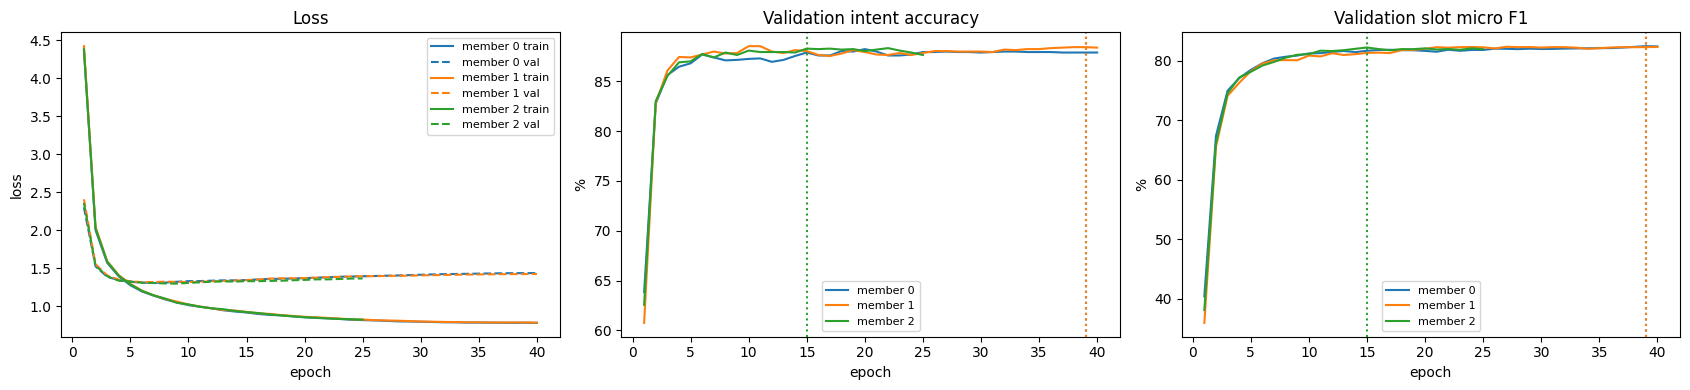

In [ ]:
#Learning curves (one line per ensemble member; dotted line = member's best epoch)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for k, hist in enumerate(member_histories):
    ep = [h["epoch"] for h in hist]
    c = f"C{k}"
    axes[0].plot(ep, [h["train_loss"] for h in hist], color=c, label=f"member {k} train")
    axes[0].plot(ep, [h["val_loss"] for h in hist], color=c, linestyle="--", label=f"member {k} val")
    axes[1].plot(ep, [h["val_intent_acc"] for h in hist], color=c, label=f"member {k}")
    axes[2].plot(ep, [h["val_slot_f1"] for h in hist], color=c, label=f"member {k}")
    for ax in axes[1:]:
        ax.axvline(member_best_epochs[k], color=c, linestyle=":")
for ax, title, ylabel in zip(axes, ["Loss", "Validation intent accuracy", "Validation slot micro F1"],
                             ["loss", "%", "%"]):
    ax.set_xlabel("epoch"); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


Stage 2: AI-Assisted Final Evaluation

In [ ]:
ckpt2 = torch.load(CKPT2_PATH, map_location=device, weights_only=False)
assert ckpt2["emb_itos"] == emb_itos and ckpt2["char2id"] == char2id, "Vocabulary differs from checkpoint"
cfg2 = ckpt2["config"]
glove_eval = make_glove_embedding(len(ckpt2["emb_itos"])).to(device)   # weights restored from checkpoint
final2 = EnsembleSystem(glove_eval, [JointBiLSTMCRF(glove_eval, cfg2)
                                     for _ in range(ckpt2["n_members"])]).to(device)
final2.load_state_dict(ckpt2["model_state"])

val_res2 = evaluate2(list(final2.members), dev_loader2, dev_proc)
test_res2 = evaluate2(list(final2.members), test_loader2, test_proc)
total2, trainable2 = count_params(final2)
assert total2 <= 20_000_000, "Parameter count exceeds 20M"
epochs2 = "/".join(str(e) for e in ckpt2["best_epochs"])

print(f"Loaded checkpoint: {CKPT2_PATH} ({ckpt2['selected']}, best epoch(s) {epochs2})")
print(f"Validation | intent acc: {val_res2['intent_acc']:.2f} | slot F1: {val_res2['slot_f1']:.2f} | "
      f"combined: {val_res2['combined']:.2f}")
print(f"Test       | intent acc: {test_res2['intent_acc']:.2f} | slot F1: {test_res2['slot_f1']:.2f} | "
      f"combined: {test_res2['combined']:.2f}")
assert round(val_res2["combined"], 2) == round(ckpt2["val_scores"]["combined"], 2), \
    "Validation score does not match the selected checkpoint"

rows = []
if all(name in globals() for name in ("final_model", "val_res", "test_res", "ckpt")):
    s1_total, s1_trainable = count_params(final_model)
    rows += [("Stage-1 system", split, s1_total, s1_trainable, res, ckpt["epoch"])
             for split, res in [("Validation", val_res), ("Test", test_res)]]
rows += [("Stage-2 system", split, total2, trainable2, res, epochs2)
         for split, res in [("Validation", val_res2), ("Test", test_res2)]]
print(f"\n{'Model':<16}{'Split':<12}{'Total params':>14}{'Trainable':>14}{'Intent acc':>12}{'Slot F1':>10}{'Epochs':>10}")
for name, split, tot, trn, res, ep in rows:
    print(f"{name:<16}{split:<12}{tot:>14,}{trn:>14,}{res['intent_acc']:>12.2f}{res['slot_f1']:>10.2f}{str(ep):>10}")


Loaded checkpoint: /content/drive/MyDrive/SC4002/stage2_best.pt (ensemble, best epoch(s) 39/39/15)
Validation | intent acc: 88.93 | slot F1: 83.17 | combined: 86.05
Test       | intent acc: 87.22 | slot F1: 81.84 | combined: 84.53

Model           Split         Total params     Trainable  Intent acc   Slot F1    Epochs
Stage-1 system  Validation       7,096,811     7,096,811       84.46     75.51        22
Stage-1 system  Test             7,096,811     7,096,811       82.68     72.73        22
Stage-2 system  Validation      17,923,383    12,908,283       88.93     83.17  39/39/15
Stage-2 system  Test            17,923,383    12,908,283       87.22     81.84  39/39/15


In [ ]:
# Error analysis of the Stage-2 system on the test split (material for the report)
_, test_pred_intents, test_pred_spans = predict2(list(final2.members), test_loader2, test_proc)
intent_err = [(ex, p) for ex, p in zip(test_proc, test_pred_intents) if p != ex["intent"]]
slot_err = [(ex, p) for ex, p in zip(test_proc, test_pred_spans) if p != ex["gold_spans"]]
print(f"Intent errors: {len(intent_err)}/{len(test_proc)} | "
      f"utterances with slot errors: {len(slot_err)}/{len(test_proc)}")

print("\nMost frequent intent confusions (gold -> predicted):")
for (g, p), c in Counter((ex["intent"], p) for ex, p in intent_err).most_common(10):
    print(f"  {c:3d}  {g} -> {p}")

tp, fp, fn = Counter(), Counter(), Counter()
for ex, pred in zip(test_proc, test_pred_spans):
    for s in pred & ex["gold_spans"]: tp[s[0]] += 1
    for s in pred - ex["gold_spans"]: fp[s[0]] += 1
    for s in ex["gold_spans"] - pred: fn[s[0]] += 1
print("\nLowest-F1 slot types (test support >= 10):")
supported = [t for t in set(tp) | set(fn) if tp[t] + fn[t] >= 10]
for t in sorted(supported, key=lambda t: 2 * tp[t] / (2 * tp[t] + fp[t] + fn[t]))[:10]:
    print(f"  {t:<20} F1 {200 * tp[t] / (2 * tp[t] + fp[t] + fn[t]):6.2f} | support {tp[t] + fn[t]:4d}")

print("\nEffect of words unseen in training:")
for has_oov in (True, False):
    idx = [i for i, ex in enumerate(test_proc)
           if any(t.lower() not in word2id for t in ex["tokens"]) == has_oov]
    acc = intent_accuracy([test_pred_intents[i] for i in idx], [test_proc[i]["intent"] for i in idx])
    f1 = slot_micro_f1([test_pred_spans[i] for i in idx], [test_proc[i]["gold_spans"] for i in idx])
    print(f"  {'with' if has_oov else 'without'} unseen words: {len(idx):4d} utterances | "
          f"intent acc {acc:.2f} | slot F1 {f1:.2f}")

rng = random.Random(SEED)
print("\nSample intent errors:")
for ex, p in rng.sample(intent_err, min(6, len(intent_err))):
    print(f"  '{' '.join(ex['tokens'])}' | gold {ex['intent']} | pred {p}")
print("\nSample slot errors:")
for ex, p in rng.sample(slot_err, min(6, len(slot_err))):
    print(f"  '{' '.join(ex['tokens'])}'\n     gold {sorted(ex['gold_spans'])}\n     pred {sorted(p)}")


Intent errors: 380/2974 | utterances with slot errors: 634/2974

Most frequent intent confusions (gold -> predicted):
   15  general_quirky -> qa_factoid
   15  qa_factoid -> general_quirky
    9  general_quirky -> calendar_query
    8  general_quirky -> news_query
    7  news_query -> general_quirky
    7  calendar_set -> calendar_query
    6  qa_definition -> general_quirky
    6  social_post -> general_quirky
    5  recommendation_movies -> general_quirky
    4  music_likeness -> play_music

Lowest-F1 slot types (test support >= 10):
  playlist_name        F1  51.85 | support   16
  podcast_descriptor   F1  55.56 | support   24
  news_topic           F1  56.84 | support   49
  audiobook_name       F1  57.14 | support   23
  podcast_name         F1  58.82 | support   17
  player_setting       F1  60.32 | support   39
  song_name            F1  62.65 | support   39
  personal_info        F1  64.00 | support   14
  radio_name           F1  64.71 | support   33
  business_type        F1

## Stage 1 (basic version): logistic regression intent classifier + linear-chain CRF slot tagger

A deliberately simple Stage-1 system. Both models are linear, start from zero weights, and are trained on the GPU using only the official training split. No word vectors or pretrained models are used.

- **Task 1, intent:** multinomial logistic regression over a binary bag of lower-cased unigrams and bigrams. It is trained full-batch with Adam on cross-entropy plus an L2 penalty.
- **Task 2, slots:** a linear-chain CRF over the BIO tags. Each token's features are the current word, the previous word and the next word. It is trained on the CRF negative log-likelihood plus an L2 penalty and decoded with Viterbi.
- **Basic tuning:** only the L2 strength is tuned for each model, plus the epoch for the CRF. Selection uses the validation split, with intent accuracy for the classifier and slot micro F1 for the tagger. The test split is evaluated once at the end.
- **Output:** every utterance gets an intent label and a set of (slot type, slot span) pairs. Both are scored with the shared evaluation functions above.

**Run order in a fresh Colab session:** use a GPU runtime. Run the cells for mounting, data loading, setup, preprocessing and shared evaluation functions, then the cells below in order. The CNN/BiLSTM Stage-1 cells and the Stage-2 cells are not needed. If the Stage-2 cells have already run, the final table also lists the Stage-2 system for comparison.

Task 1: logistic regression intent classifier, tuned on validation intent accuracy

In [6]:
# Basic Stage 1, Task 1: logistic regression intent classifier over a bag of unigrams and bigrams
assert device.type == "cuda", "Use a GPU runtime: Runtime > Change runtime type > GPU"
BASIC_DIR = "/content/drive/MyDrive/SC4002"
os.makedirs(BASIC_DIR, exist_ok=True)

def l2_penalty(model):
    """Sum of squared weights of every parameter (plain L2 regularisation)."""
    return sum((p ** 2).sum() for p in model.parameters())

def ngram_features(tokens):
    """Binary bag of lower-cased unigrams and bigrams; <s> and </s> mark the utterance boundaries."""
    words = [t.lower() for t in tokens]
    padded = ["<s>"] + words + ["</s>"]
    return set(words) | {a + " " + b for a, b in zip(padded, padded[1:])}

# Feature vocabulary from the training split only; n-grams never seen in training are ignored
feat2id = {}
for ex in train_proc:
    for f in sorted(ngram_features(ex["tokens"])):
        feat2id.setdefault(f, len(feat2id))

def bag_tensors(proc):
    """Flat feature ids and offsets (the input format of nn.EmbeddingBag) plus intent labels."""
    ids, offsets = [], []
    for ex in proc:
        offsets.append(len(ids))
        ids.extend(feat2id[f] for f in ngram_features(ex["tokens"]) if f in feat2id)
    labels = torch.tensor([intent2id[ex["intent"]] for ex in proc], device=device)
    return torch.tensor(ids, device=device), torch.tensor(offsets, device=device), labels

X_tr, O_tr, y_tr = bag_tensors(train_proc)
X_dev, O_dev, y_dev = bag_tensors(dev_proc)
X_test, O_test, y_test = bag_tensors(test_proc)


class BoWLogReg(nn.Module):
    """Multinomial logistic regression: logits = W x + b, where x is the binary n-gram bag."""
    def __init__(self, n_feats, n_classes):
        super().__init__()
        self.W = nn.EmbeddingBag(n_feats, n_classes, mode="sum")   # sum of W rows = W x for a sparse x
        nn.init.zeros_(self.W.weight)
        self.b = nn.Parameter(torch.zeros(n_classes))

    def forward(self, ids, offsets):
        return self.W(ids, offsets) + self.b


LOGREG_CONFIG = {"l2_grid": [0.0, 1e-5, 1e-4, 1e-3], "lr": 0.05, "steps": 300}

def train_logreg(l2, cfg=LOGREG_CONFIG):
    """Full-batch Adam on cross-entropy + l2 * ||w||^2 (the problem is convex, so it simply converges)."""
    set_seed()
    model = BoWLogReg(len(feat2id), len(intent2id)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    for _ in range(cfg["steps"]):
        loss = F.cross_entropy(model(X_tr, O_tr), y_tr) + l2 * l2_penalty(model)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model, loss.item()

@torch.no_grad()
def logreg_predict(model, ids, offsets):
    model.eval()
    return [id2intent[i] for i in model(ids, offsets).argmax(-1).tolist()]

# Basic tuning: pick the L2 strength with the highest validation intent accuracy
dev_gold_intents = [ex["intent"] for ex in dev_proc]
logreg_runs = {}
for l2 in LOGREG_CONFIG["l2_grid"]:
    t0 = time.time()
    m, train_loss = train_logreg(l2)
    acc = intent_accuracy(logreg_predict(m, X_dev, O_dev), dev_gold_intents)
    logreg_runs[l2] = {"model": m, "val_intent_acc": acc}
    print(f"L2 {l2:<7g} | final train loss {train_loss:.4f} | val intent acc {acc:.2f} | {time.time() - t0:.1f}s")

best_logreg_l2 = max(logreg_runs, key=lambda k: logreg_runs[k]["val_intent_acc"])
logreg_model = logreg_runs[best_logreg_l2]["model"]
print(f"\nFeatures: {len(feat2id):,} n-grams | params: {sum(p.numel() for p in logreg_model.parameters()):,}")
print(f"Selected L2 = {best_logreg_l2:g} | val intent acc {logreg_runs[best_logreg_l2]['val_intent_acc']:.2f}")

L2 0       | final train loss 0.0012 | val intent acc 82.14 | 5.8s
L2 1e-05   | final train loss 0.1678 | val intent acc 84.41 | 0.6s
L2 0.0001  | final train loss 0.6892 | val intent acc 83.82 | 0.6s
L2 0.001   | final train loss 1.9106 | val intent acc 74.67 | 0.6s

Features: 32,785 n-grams | params: 1,967,160
Selected L2 = 1e-05 | val intent acc 84.41


Task 2: linear-chain CRF slot tagger, tuned on validation slot micro F1

In [7]:
# Basic Stage 1, Task 2: linear-chain CRF slot tagger over BIO tags
# Features of token t: the current word, the previous word and the next word (one weight per word and tag).
BOS_ID, EOS_ID = len(word2id), len(word2id) + 1     # extra word ids for "before the start" / "after the end"
N_WORDS, N_TAGS = len(word2id) + 2, len(slot2id)

def crf_encode(ex):
    cur = [word2id.get(t.lower(), word2id[UNK]) for t in ex["tokens"]]
    return {"cur": cur, "prev": [BOS_ID] + cur[:-1], "next": cur[1:] + [EOS_ID],
            "tags": [slot2id[t] for t in ex["slot_tags"]]}

def crf_collate(batch):
    def pad(key):
        return pad_sequence([torch.tensor(b[key]) for b in batch], batch_first=True, padding_value=0)
    lengths = torch.tensor([len(b["cur"]) for b in batch])
    mask = torch.arange(lengths.max())[None, :] < lengths[:, None]
    return {"cur": pad("cur"), "prev": pad("prev"), "next": pad("next"), "tags": pad("tags"),
            "lengths": lengths, "mask": mask}

def crf_to_device(batch):
    return {k: v.to(device) for k, v in batch.items()}

crf_train_data = [crf_encode(ex) for ex in train_proc]
crf_dev_loader = DataLoader([crf_encode(ex) for ex in dev_proc], batch_size=256, collate_fn=crf_collate)
crf_test_loader = DataLoader([crf_encode(ex) for ex in test_proc], batch_size=256, collate_fn=crf_collate)


class LinearCRF(nn.Module):
    """score(x, y) = sum_t [emit(t, y_t) + trans(y_{t-1}, y_t)] + start(y_1) + end(y_T), with
    emit(t, y) = w_cur[x_t, y] + w_prev[x_{t-1}, y] + w_next[x_{t+1}, y] + b[y]."""
    def __init__(self, n_words, n_tags):
        super().__init__()
        self.w_cur = nn.Embedding(n_words, n_tags, padding_idx=0)
        self.w_prev = nn.Embedding(n_words, n_tags, padding_idx=0)
        self.w_next = nn.Embedding(n_words, n_tags, padding_idx=0)
        for table in (self.w_cur, self.w_prev, self.w_next):
            nn.init.zeros_(table.weight)
        self.bias = nn.Parameter(torch.zeros(n_tags))
        self.trans = nn.Parameter(torch.zeros(n_tags, n_tags))      # trans[i, j]: tag i followed by tag j
        self.start = nn.Parameter(torch.zeros(n_tags))
        self.end = nn.Parameter(torch.zeros(n_tags))

    def emissions(self, b):
        return self.w_cur(b["cur"]) + self.w_prev(b["prev"]) + self.w_next(b["next"]) + self.bias  # (B, T, N)

    def nll(self, b):
        """Mean negative log-likelihood of the gold tag sequences (forward algorithm)."""
        em, tags, mask = self.emissions(b), b["tags"], b["mask"]
        maskf = mask.float()
        gold = self.start[tags[:, 0]] + (em.gather(2, tags.unsqueeze(2)).squeeze(2) * maskf).sum(1)
        gold = gold + (self.trans[tags[:, :-1], tags[:, 1:]] * maskf[:, 1:]).sum(1)
        gold = gold + self.end[tags.gather(1, (b["lengths"] - 1).unsqueeze(1)).squeeze(1)]
        alpha = self.start + em[:, 0]                                  # (B, N)
        for t in range(1, em.size(1)):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + self.trans, dim=1) + em[:, t]
            alpha = torch.where(mask[:, t:t + 1], nxt, alpha)
        return (torch.logsumexp(alpha + self.end, dim=1) - gold).mean()

    @torch.no_grad()
    def decode(self, b):
        """Viterbi: highest-scoring tag sequence (B, T); padded positions repeat the last real tag."""
        em, mask = self.emissions(b), b["mask"]
        B, T, N = em.shape
        score = self.start + em[:, 0]
        keep = torch.arange(N, device=em.device).expand(B, N)
        backptrs = []
        for t in range(1, T):
            best, idx = (score.unsqueeze(2) + self.trans).max(dim=1)
            m = mask[:, t:t + 1]
            score = torch.where(m, best + em[:, t], score)
            backptrs.append(torch.where(m, idx, keep))
        tag = (score + self.end).argmax(dim=1)
        path = [tag]
        for bp in reversed(backptrs):
            tag = bp.gather(1, tag.unsqueeze(1)).squeeze(1)
            path.append(tag)
        return torch.stack(path[::-1], dim=1)


def crf_predict(model, loader, proc):
    """Predicted (slot type, span) sets in dataset order."""
    model.eval()
    spans, idx = [], 0
    for b in loader:
        b = crf_to_device(b)
        for row, L in zip(model.decode(b).tolist(), b["lengths"].tolist()):
            spans.append(tags_to_spans(proc[idx]["tokens"], [id2slot[t] for t in row[:L]]))
            idx += 1
    return spans


CRF_CONFIG = {"l2_grid": [0.0, 1e-5, 1e-4], "lr": 0.05, "batch_size": 64, "epochs": 15}

# Basic tuning: for each L2 strength train for a fixed number of epochs; keep the epoch and L2
# with the highest validation slot micro F1
dev_gold_spans = [ex["gold_spans"] for ex in dev_proc]
crf_history = {}
crf_best = {"val_slot_f1": -1.0}
start = time.time()
for l2 in CRF_CONFIG["l2_grid"]:
    set_seed()
    model_crf = LinearCRF(N_WORDS, N_TAGS).to(device)
    optimizer = torch.optim.Adam(model_crf.parameters(), lr=CRF_CONFIG["lr"])
    loader = DataLoader(crf_train_data, batch_size=CRF_CONFIG["batch_size"], shuffle=True,
                        collate_fn=crf_collate, generator=torch.Generator().manual_seed(SEED))
    crf_history[l2] = []
    for epoch in range(1, CRF_CONFIG["epochs"] + 1):
        model_crf.train()
        total, n = 0.0, 0
        for b in loader:
            b = crf_to_device(b)
            loss = model_crf.nll(b) + l2 * l2_penalty(model_crf)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item(); n += 1
        f1 = slot_micro_f1(crf_predict(model_crf, crf_dev_loader, dev_proc), dev_gold_spans)
        crf_history[l2].append({"epoch": epoch, "train_loss": total / n, "val_slot_f1": f1})
        if f1 > crf_best["val_slot_f1"]:
            crf_best = {"l2": l2, "epoch": epoch, "val_slot_f1": f1,
                        "state": {k: v.detach().clone() for k, v in model_crf.state_dict().items()}}
    best_ep = max(crf_history[l2], key=lambda h: h["val_slot_f1"])
    print(f"L2 {l2:<7g} | best epoch {best_ep['epoch']:2d} | val slot F1 {best_ep['val_slot_f1']:.2f} | "
          f"final train loss {crf_history[l2][-1]['train_loss']:.4f}")

print(f"\nCRF tuning time: {time.time() - start:.1f}s | params: {sum(p.numel() for p in model_crf.parameters()):,}")
print(f"Selected L2 = {crf_best['l2']:g}, epoch {crf_best['epoch']} | val slot F1 {crf_best['val_slot_f1']:.2f}")

L2 0       | best epoch  3 | val slot F1 77.38 | final train loss 0.1920
L2 1e-05   | best epoch  9 | val slot F1 77.40 | final train loss 1.1353
L2 0.0001  | best epoch 15 | val slot F1 69.73 | final train loss 3.0134

CRF tuning time: 113.1s | params: 1,779,552
Selected L2 = 1e-05, epoch 9 | val slot F1 77.40


Tuning curves

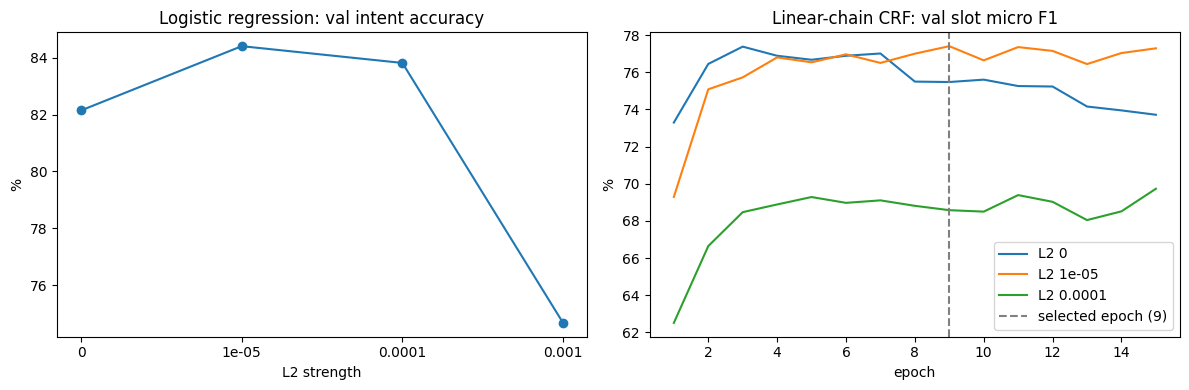

In [8]:
# Tuning curves: validation intent accuracy per L2 strength, and CRF validation slot F1 per epoch
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grid = LOGREG_CONFIG["l2_grid"]
axes[0].plot(range(len(grid)), [logreg_runs[l2]["val_intent_acc"] for l2 in grid], marker="o")
axes[0].set_xticks(range(len(grid)), [f"{l2:g}" for l2 in grid])
axes[0].set_xlabel("L2 strength"); axes[0].set_ylabel("%"); axes[0].set_title("Logistic regression: val intent accuracy")
for l2, hist in crf_history.items():
    axes[1].plot([h["epoch"] for h in hist], [h["val_slot_f1"] for h in hist], label=f"L2 {l2:g}")
axes[1].axvline(crf_best["epoch"], color="gray", linestyle="--", label=f"selected epoch ({crf_best['epoch']})")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("%"); axes[1].set_title("Linear-chain CRF: val slot micro F1")
axes[1].legend()
plt.tight_layout(); plt.show()

Final evaluation of the basic Stage-1 system on validation and test

In [9]:
# Save the selected models, reload them, and evaluate once on validation and test
BASIC_CKPT = os.path.join(BASIC_DIR, "stage1_basic_best.pt")
torch.save({"logreg_state": logreg_model.state_dict(), "logreg_l2": best_logreg_l2,
            "crf_state": crf_best["state"], "crf_l2": crf_best["l2"], "crf_epoch": crf_best["epoch"],
            "feat2id": feat2id, "word2id": word2id, "intent2id": intent2id, "slot2id": slot2id}, BASIC_CKPT)

ckpt_basic = torch.load(BASIC_CKPT, map_location=device, weights_only=False)
assert ckpt_basic["feat2id"] == feat2id and ckpt_basic["word2id"] == word2id, "Vocabulary differs from checkpoint"
basic_logreg = BoWLogReg(len(feat2id), len(intent2id)).to(device)
basic_logreg.load_state_dict(ckpt_basic["logreg_state"])
basic_crf = LinearCRF(N_WORDS, N_TAGS).to(device)
basic_crf.load_state_dict(ckpt_basic["crf_state"])

def evaluate_basic(proc, ids, offsets, crf_loader):
    """Every utterance gets an intent label and a set of (slot type, slot span) pairs."""
    pred_intents = logreg_predict(basic_logreg, ids, offsets)
    pred_spans = crf_predict(basic_crf, crf_loader, proc)
    acc = intent_accuracy(pred_intents, [ex["intent"] for ex in proc])
    f1 = slot_micro_f1(pred_spans, [ex["gold_spans"] for ex in proc])
    return {"intent_acc": acc, "slot_f1": f1, "combined": (acc + f1) / 2,
            "pred_intents": pred_intents, "pred_spans": pred_spans}

val_basic = evaluate_basic(dev_proc, X_dev, O_dev, crf_dev_loader)
test_basic = evaluate_basic(test_proc, X_test, O_test, crf_test_loader)
assert round(val_basic["intent_acc"], 2) == round(logreg_runs[best_logreg_l2]["val_intent_acc"], 2)
assert round(val_basic["slot_f1"], 2) == round(crf_best["val_slot_f1"], 2)

basic_total = sum(p.numel() for p in basic_logreg.parameters()) + sum(p.numel() for p in basic_crf.parameters())
basic_trainable = sum(p.numel() for m in (basic_logreg, basic_crf) for p in m.parameters() if p.requires_grad)
assert basic_total <= 20_000_000, "Parameter count exceeds 20M"

print(f"Loaded checkpoint: {BASIC_CKPT}")
print(f"Logistic regression: L2 {ckpt_basic['logreg_l2']:g} | CRF: L2 {ckpt_basic['crf_l2']:g}, "
      f"epoch {ckpt_basic['crf_epoch']}")
print(f"Validation | intent acc: {val_basic['intent_acc']:.2f} | slot F1: {val_basic['slot_f1']:.2f} | "
      f"combined: {val_basic['combined']:.2f}")
print(f"Test       | intent acc: {test_basic['intent_acc']:.2f} | slot F1: {test_basic['slot_f1']:.2f} | "
      f"combined: {test_basic['combined']:.2f}")

rows = [("Stage-1 basic", split, basic_total, basic_trainable, res)
        for split, res in [("Validation", val_basic), ("Test", test_basic)]]
if all(name in globals() for name in ("val_res2", "test_res2", "total2", "trainable2")):
    rows += [("Stage-2 system", split, total2, trainable2, res)
             for split, res in [("Validation", val_res2), ("Test", test_res2)]]
print(f"\n{'Model':<16}{'Split':<12}{'Total params':>14}{'Trainable':>14}{'Intent acc':>12}{'Slot F1':>10}")
for name, split, tot, trn, res in rows:
    print(f"{name:<16}{split:<12}{tot:>14,}{trn:>14,}{res['intent_acc']:>12.2f}{res['slot_f1']:>10.2f}")

print("\nExample outputs (test):")
for i in range(3):
    ex = test_proc[i]
    print(f"  '{' '.join(ex['tokens'])}'")
    print(f"     gold: {ex['intent']} {sorted(ex['gold_spans'])}")
    print(f"     pred: {test_basic['pred_intents'][i]} {sorted(test_basic['pred_spans'][i])}")

Loaded checkpoint: /content/drive/MyDrive/SC4002/stage1_basic_best.pt
Logistic regression: L2 1e-05 | CRF: L2 1e-05, epoch 9
Validation | intent acc: 84.41 | slot F1: 77.40 | combined: 80.91
Test       | intent acc: 83.56 | slot F1: 74.09 | combined: 78.82

Model           Split         Total params     Trainable  Intent acc   Slot F1
Stage-1 basic   Validation       3,746,712     3,746,712       84.41     77.40
Stage-1 basic   Test             3,746,712     3,746,712       83.56     74.09

Example outputs (test):
  'wake me up at five am this week'
     gold: alarm_set [('date', 'this week'), ('time', 'five am')]
     pred: alarm_set [('date', 'this week'), ('time', 'five am')]
  'quiet'
     gold: audio_volume_mute []
     pred: audio_volume_mute []
  'pink is all we need'
     gold: iot_hue_lightchange [('color_type', 'pink')]
     pred: weather_query []
